## 1. Parameter Estimation & Functional Models

### Keplerian Orbit Parameter Estimation
The `scipy.optimize.curve_fit` module can be used to estimate the parameters of a planet in a Keplerian orbit using non-linear least squares. This implementation maps the dependent spatial variable to the six parameters identified in standard astrophysical models: semi-major axis, eccentricity, inclination, ascending node longitude, argument of periastron, and true anomaly. Here, the true anomaly serves as the independent time-varying observation.

In [6]:
import numpy as np
from scipy.optimize import curve_fit

def keplerian_radius(true_anomaly, a, e):
    """
    Computes the orbital radius of a planet from the star.
    The model uses the semi-major axis (a), eccentricity (e), and true anomaly.
    (Note: Inclination, ascending node, and argument of periastron are excluded here 
    as they dictate 3D orientation rather than scalar radial distance).
    """
    return a * (1 - e**2) / (1 + e * np.cos(true_anomaly))

# 1. Generate simulated true anomaly data (independent variable)
theta_data = np.linspace(0, 2 * np.pi, 100)

# 2. Simulate observations with true parameters (a = 1.0 AU, e = 0.05)
true_a = 1.0
true_e = 0.05
r_true = keplerian_radius(theta_data, true_a, true_e)

# 3. Inject Gaussian measurement noise
np.random.seed(42)
r_obs = r_true + np.random.normal(0, 0.02, size=len(theta_data))

# 4. Perform parameter estimation to find the "best" values based on observations
initial_guess = [1.0, 0.0] # Initial guess for a and e
estimated_params, covariance = curve_fit(keplerian_radius, theta_data, r_obs, p0=initial_guess)

print(f"Estimated semi-major axis: {estimated_params[0]:.3f} AU")
print(f"Estimated eccentricity: {estimated_params[1]:.3f}")

Estimated semi-major axis: 0.998 AU
Estimated eccentricity: 0.049


### Stellar Atmosphere Spectral Fitting
Mathematical statistics can instantiate deterministic functional relationships established by physical processes, such as a spectrum from a stellar atmosphere. This implementation fits a simple absorption line model to noisy spectral data.

In [7]:
import numpy as np
from scipy.optimize import curve_fit

def stellar_spectrum(wavelength, continuum, amplitude, center, width):
    """
    Models a deterministic functional relationship for a stellar spectrum using a Gaussian absorption line.
    """
    absorption = amplitude * np.exp(-0.5 * ((wavelength - center) / width)**2)
    return continuum - absorption

# 1. Simulate independent wavelength data (in nanometers)
wavelengths = np.linspace(400, 700, 200)

# 2. Simulate true spectrum parameters
flux_true = stellar_spectrum(wavelengths, continuum=1.0, amplitude=0.5, center=550.0, width=15.0)

# 3. Add Gaussian measurement noise
flux_obs = flux_true + np.random.normal(0, 0.03, size=len(wavelengths))

# 4. Estimate the best-fit parameters for the functional relationship
initial_guess = [1.0, 0.5, 500.0, 10.0]
popt, pcov = curve_fit(stellar_spectrum, wavelengths, flux_obs, p0=initial_guess)

print(f"Estimated Continuum: {popt[0]:.2f}")
print(f"Estimated Absorption Amplitude: {popt[1]:.2f}")
print(f"Estimated Line Center: {popt[2]:.1f} nm")

Estimated Continuum: 0.91
Estimated Absorption Amplitude: -0.11
Estimated Line Center: 445.9 nm


## 2. Model Selection & Goodness-of-Fit

### Information Criteria for Nested Models: Stellar Photometry
When comparing nested models, such as whether stellar photometry is best described by a simple blackbody or a blackbody with absorption, we can use the Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC) to balance conformity to the data against the penalty of added complexity. The AIC formulation maximizes $2l(\hat{\theta}_j) - 2p_j$, where $l$ is the log-likelihood and $p_j$ is the number of parameters.

In [8]:
import numpy as np
from scipy.optimize import curve_fit

# Simulated photometric data
wavelengths = np.linspace(300, 1000, 100)
np.random.seed(42)

def blackbody_model(wav, t, norm):
    """Simple blackbody model (simplified Planck function approximation for code brevity)."""
    return norm / (wav**5 * (np.exp(1e4 / (wav * t)) - 1))

def blackbody_absorption_model(wav, t, norm, abs_center, abs_depth):
    """Nested model: Blackbody with a Gaussian absorption feature."""
    bb = blackbody_model(wav, t, norm)
    absorption = 1 - abs_depth * np.exp(-0.5 * ((wav - abs_center)/20)**2)
    return bb * absorption

# Generate mock data using the more complex model
y_true = blackbody_absorption_model(wavelengths, 5000, 1e8, 600, 0.3)
y_obs = y_true + np.random.normal(0, 0.05, size=len(wavelengths))

# Fit Model 1 (Simple)
popt1, _ = curve_fit(blackbody_model, wavelengths, y_obs, p0=[5000, 1e8])
resid1 = y_obs - blackbody_model(wavelengths, *popt1)
log_lik1 = -0.5 * np.sum((resid1 / 0.05)**2)

# Fit Model 2 (Complex)
popt2, _ = curve_fit(blackbody_absorption_model, wavelengths, y_obs, p0=[5000, 1e8, 600, 0.3])
resid2 = y_obs - blackbody_absorption_model(wavelengths, *popt2)
log_lik2 = -0.5 * np.sum((resid2 / 0.05)**2)

def calc_aic_bic(log_l, p, n):
    """Calculates AIC and BIC where the maximum value identifies the preferred model."""
    aic = 2 * log_l - 2 * p
    bic = 2 * log_l - p * np.log(n)
    return aic, bic

aic1, bic1 = calc_aic_bic(log_lik1, len(popt1), len(y_obs))
aic2, bic2 = calc_aic_bic(log_lik2, len(popt2), len(y_obs))

print(f"Model 1 (Simple)  - AIC: {aic1:.1f}, BIC: {bic1:.1f}")
print(f"Model 2 (Complex) - AIC: {aic2:.1f}, BIC: {bic2:.1f}")

Model 1 (Simple)  - AIC: -86.7, BIC: -91.9
Model 2 (Complex) - AIC: -89.6, BIC: -100.0


### Nonnested Model Selection: Quasar Continuum
Comparing different model families, such as modeling the continuum emission of a quasar as a power-law (nonthermal relativistic jet) versus a multiple-temperature blackbody (thermal accretion disk), requires nonnested model selection. AIC and BIC treat all models symmetrically and do not require the assumption that one candidate is the "correct" null hypothesis, allowing direct comparison of these distinct functional forms

In [9]:
def power_law_model(wav, alpha, norm):
    """Nonthermal relativistic jet model."""
    return norm * wav**(-alpha)

# Fit Nonnested Model (Power Law) to the same simulated data
popt3, _ = curve_fit(power_law_model, wavelengths, y_obs, p0=[1.5, 1e4], maxfev=10000)
resid3 = y_obs - power_law_model(wavelengths, *popt3)
log_lik3 = -0.5 * np.sum((resid3 / 0.05)**2)

aic3, bic3 = calc_aic_bic(log_lik3, len(popt3), len(y_obs))

print(f"Model 3 (Power Law) - AIC: {aic3:.1f}, BIC: {bic3:.1f}")
# The maximum AIC/BIC value among the thermal and nonthermal fits dictates the optimal model.

Model 3 (Power Law) - AIC: -85.4, BIC: -90.6


## 3. Bayesian Inference & Complex Priors

## Binomial Proportion: AGN Radio-Loudness
When estimating the prevalence of radio-loud active galactic nuclei (AGN) from a binary dataset (radio detection vs. nondetection), incorporating prior knowledge stabilizes the estimate. If the prior probability of radio-loudness is modeled with a Beta distribution (a natural conjugate prior for the Binomial likelihood), the posterior distribution is also a Beta distribution.

In [10]:
import numpy as np
from scipy.stats import beta

# 1. Define the observational data for the AGN sample
n_trials = 50       # Total optically selected AGN surveyed
x_successes = 12    # Number of positive radio detections

# 2. Define prior knowledge (e.g., expected prevalence is around 10%)
# A Beta(2, 18) distribution has a mean of 2/(2+18) = 0.1
alpha_prior = 2.0
gamma_prior = 18.0

# 3. Calculate the posterior distribution parameters
# For a Binomial likelihood and Beta prior, the posterior is Beta(x + alpha, n - x + gamma)
alpha_post = x_successes + alpha_prior
gamma_post = n_trials - x_successes + gamma_prior

# 4. Extract Bayesian point estimates
posterior_mean = alpha_post / (alpha_post + gamma_post)

# 5. Calculate the 95% highest posterior density (HPD) credible interval
credible_interval = beta.interval(0.95, alpha_post, gamma_post)

print(f"Prior Mean: {alpha_prior / (alpha_prior + gamma_prior):.3f}")
print(f"Sample Mean (MLE): {x_successes / n_trials:.3f}")
print(f"Posterior Mean (Bayesian): {posterior_mean:.3f}")
print(f"95% Credible Interval: {credible_interval[0]:.3f} - {credible_interval[1]:.3f}")

Prior Mean: 0.100
Sample Mean (MLE): 0.240
Posterior Mean (Bayesian): 0.200
95% Credible Interval: 0.116 - 0.301


### Univariate Signal Estimation: Gaussian Distributions
When measuring an astronomical signal subject to Gaussian noise, Bayesian inference combines the sample mean with an assumed prior distribution. If the prior is normally distributed, the posterior distribution is also normal, yielding an estimator that is a convex combination of the prior mean and the sample mean.

In [11]:
import numpy as np
import scipy.stats as stats

# 1. Simulate independent signal measurements (signal + noise)
np.random.seed(42)
true_signal = 8.0
noise_sigma = 2.5
n_obs = 30
observations = np.random.normal(true_signal, noise_sigma, n_obs)
sample_mean = np.mean(observations)

# 2. Define an informative prior for the signal strength: Normal(mu_0, tau^2)
mu_0 = 5.0
tau = 1.5

# 3. Calculate the posterior parameters
# The posterior variance (gamma^2) and mean (mu_hat) for a known observation variance
gamma_sq = (noise_sigma**2 / n_obs) * (tau**2) / (tau**2 + noise_sigma**2 / n_obs)
gamma = np.sqrt(gamma_sq)

mu_hat = gamma_sq * (mu_0 / tau**2 + n_obs * sample_mean / noise_sigma**2)

# 4. Calculate the 95% credible interval using the posterior normal distribution
ci_lower = mu_hat - 1.96 * gamma
ci_upper = mu_hat + 1.96 * gamma

print(f"Prior Mean: {mu_0:.3f}")
print(f"Sample Mean (MLE): {sample_mean:.3f}")
print(f"Posterior Mean (HPD): {mu_hat:.3f}")
print(f"95% Credible Interval: [{ci_lower:.3f}, {ci_upper:.3f}]")

Prior Mean: 5.000
Sample Mean (MLE): 7.530
Posterior Mean (HPD): 7.315
95% Credible Interval: [6.459, 8.171]


## 4. Hypothesis Testing, Proportions & Signal Detection

### Binary Proportions & Confidence Intervals
In binary trial experiments, astronomers often estimate simple proportions, such as the fraction of radio-loud quasars or the ratio of brown dwarfs to stars. The maximum likelihood estimator for the unknown fraction $p$ is $y/n$, where $y$ is the number of successes in $n$ trials. When $n$ is large, asymptotic normality applies, allowing for the calculation of approximate confidence intervals.

In [13]:
import numpy as np
from scipy.stats import norm

# 1. Define the experimental data
n_quasars = 250        # Total number of quasars observed
y_radio_loud = 42      # Number of quasars detected as radio-loud

# 2. Calculate the best-fit proportion (Maximum Likelihood Estimate)
p_hat = y_radio_loud / n_quasars

# 3. Calculate the 95% confidence interval using asymptotic normality
alpha = 0.05
z_alpha_2 = norm.ppf(1 - alpha / 2) # Z-score for two-sided 95% confidence

# Standard error for a binomial proportion
standard_error = np.sqrt((p_hat * (1 - p_hat)) / n_quasars)

ci_lower = p_hat - z_alpha_2 * standard_error
ci_upper = p_hat + z_alpha_2 * standard_error

print(f"Estimated Proportion (MLE): {p_hat:.3f}")
print(f"95% Confidence Interval: [{ci_lower:.3f}, {ci_upper:.3f}]")

Estimated Proportion (MLE): 0.168
95% Confidence Interval: [0.122, 0.214]


### Signal Detection & Hypothesis Testing
Detecting weak signals in noise is a fundamental hypothesis testing problem in astronomy. The process formulates a null hypothesis ($H_0$, no signal present) against an alternative hypothesis ($H_a$, signal present). To control Type 1 errors (false positives) when searching for faint sources, a critical region is established based on a chosen significance level, often using the Central Limit Theorem for sample means.

In [14]:
import numpy as np
from scipy.stats import norm

# 1. Define the known background (null hypothesis) properties
mu_0 = 15.0       # Mean background noise level
sigma = 3.5       # Known standard deviation of the background

# 2. Define the observational data for a specific sky location
n_pixels = 40     # Number of pixels (sample size) in the extraction aperture
np.random.seed(42)
# Simulate an observation with a faint true signal (mean = 16.5)
pixel_values = np.random.normal(16.5, sigma, n_pixels)
sample_mean = np.mean(pixel_values)

# 3. Set up the one-sided hypothesis test (H1: mu > mu_0)
alpha = 0.01      # 1% significance level to strictly control false positives
z_alpha = norm.ppf(1 - alpha)

# 4. Calculate the critical region boundary
# Reject H0 if the sample mean is greater than or equal to this threshold
critical_value = mu_0 + z_alpha * (sigma / np.sqrt(n_pixels))

# 5. Evaluate the hypothesis
signal_detected = sample_mean >= critical_value

# 6. Calculate the p-value: the probability of observing a result at least this extreme by chance
z_statistic = (sample_mean - mu_0) / (sigma / np.sqrt(n_pixels))
p_value = 1 - norm.cdf(z_statistic)

print(f"Sample Mean: {sample_mean:.2f}")
print(f"Critical Threshold (alpha={alpha}): {critical_value:.2f}")
print(f"Signal Detected (H0 Rejected)? {signal_detected}")
print(f"P-value: {p_value:.4f}")

Sample Mean: 15.73
Critical Threshold (alpha=0.01): 16.29
Signal Detected (H0 Rejected)? False
P-value: 0.0921


## 5. Others

### Bootstrap Resampling Distribution
Resampling methods like the bootstrap evaluate how a statistic of interest varies by generating numerous hypothetical datasets drawn with replacement from the original observations. This computationally intensive technique constructs a distribution of the statistic, automatically correcting for skewness and providing reliable confidence intervals without relying on classical normal approximations.

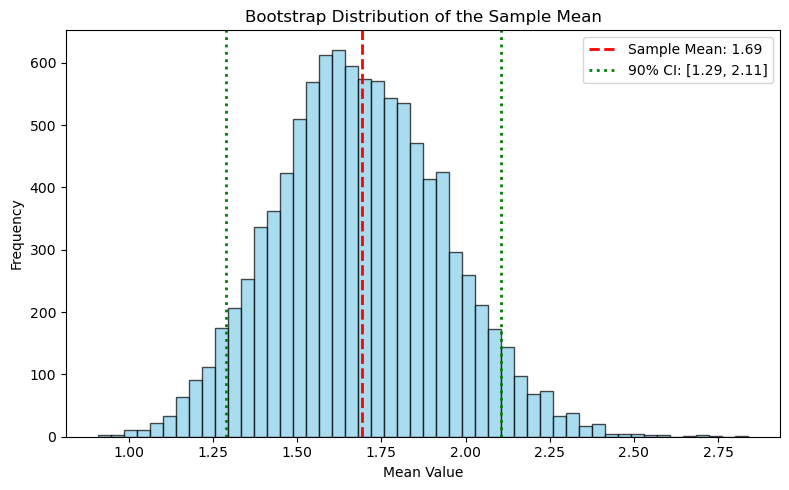

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Simulate an original astronomical dataset (e.g., non-normal exponential data)
np.random.seed(42)
original_data = np.random.exponential(scale=2.0, size=50)
sample_mean = np.mean(original_data)

# 2. Generate N bootstrap resamples with replacement
n_bootstraps = 10000
boot_means = np.zeros(n_bootstraps)

for i in range(n_bootstraps):
    # Resampling with replacement from the original data
    resample = np.random.choice(original_data, size=len(original_data), replace=True)
    boot_means[i] = np.mean(resample)

# 3. Calculate the 90% confidence interval using the bootstrap histogram
ci_lower = np.percentile(boot_means, 5)
ci_upper = np.percentile(boot_means, 95)

# 4. Plot the bootstrap distribution
plt.figure(figsize=(8, 5))
plt.hist(boot_means, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(sample_mean, color='red', linestyle='dashed', linewidth=2, label=f'Sample Mean: {sample_mean:.2f}')
plt.axvline(ci_lower, color='green', linestyle='dotted', linewidth=2, label=f'90% CI: [{ci_lower:.2f}, {ci_upper:.2f}]')
plt.axvline(ci_upper, color='green', linestyle='dotted', linewidth=2)
plt.title('Bootstrap Distribution of the Sample Mean')
plt.xlabel('Mean Value')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

### Bayesian Inference for a Binomial Proportion
Bayesian statistical inference combines a prior probability distribution with the likelihood of the observed data to produce a posterior probability distribution. For estimating the success ratio of a binary variable—such as the fraction of active galactic nuclei (AGN) that are radio-loud, a beta distribution serves as a natural conjugate prior, ensuring the posterior is also a beta distribution.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# 1. Set up the parameter space for the proportion theta (0 to 1)
theta = np.linspace(0, 1, 500)

# 2. Define the prior distribution (Beta distribution)
# Using alpha=2, gamma=18 for a prior mean of 0.1 (10% prevalence)[cite
alpha_prior = 2
gamma_prior = 18
prior_pdf = beta.pdf(theta, alpha_prior, gamma_prior)

# 3. Define the observational data and calculate Likelihood[cite: 32]
n_trials = 50
x_successes = 12
# Likelihood function for a binary variable is the binomial distribution[cite: 32]
likelihood = (theta**x_successes) * ((1 - theta)**(n_trials - x_successes))
likelihood_normalized = likelihood / np.trapz(likelihood, theta) # Normalize for plotting

# 4. Calculate the Posterior distribution[cite: 32]
alpha_post = x_successes + alpha_prior
gamma_post = n_trials - x_successes + gamma_prior
posterior_pdf = beta.pdf(theta, alpha_post, gamma_post)

# 5. Plot the Bayesian updating process
plt.figure(figsize=(8, 5))
plt.plot(theta, prior_pdf, label='Prior Distribution $P(\\theta)$', color='blue', linestyle='dashed')
plt.plot(theta, likelihood_normalized, label='Normalized Likelihood $L(X|\\theta)$', color='orange', linestyle='dotted')
plt.plot(theta, posterior_pdf, label='Posterior Distribution $P(\\theta|X)$', color='green', linewidth=2)
plt.fill_between(theta, posterior_pdf, color='green', alpha=0.2)

plt.title('Bayesian Inference: AGN Radio-Loudness Proportion')
plt.xlabel('Proportion Parameter $\\theta$')
plt.ylabel('Probability Density')
plt.xlim(0, 0.5)
plt.legend()
plt.tight_layout()
plt.show()